# 08 · Model B460: noise-augmented training on 464 h
**Project:** Noise-Robust Speech Recognition with Word-Level Error Detection (Group 9) · Milestone 4

**Why we trained it.** After the recipe was fixed, the largest remaining lever was **more labelled data**. B460 is a fresh fine-tune of
wav2vec2-base on train-clean-100 + train-clean-360 (**464 h**, 1,172 speakers) with B's noise recipe and B2's
learning rate (1e-4), for 80k steps (≈ 28 epochs, ≈ 8 GPU-hours).

**Recipe.** As B2 (lr 1e-4), on train_460, 80k steps, 5 % warm-up.

| | |
|---|---|
| Run name | `B460` |
| Config | `configs/train_B460.yaml` (saved copy with all defaults: `experiments/runs/B460/config.json`) |
| Training / validation logs | `experiments/runs/B460/train_log.csv`, `eval_log.csv` |
| Test results | `experiments/results/B460/` (greedy), `B460_lm4/` (4-gram LM), `B460_ext/` (reverb, −5 dB) |
| Trained model | [wav2vec2-base-ls460-noise-aug](https://huggingface.co/kumargulshan/wav2vec2-base-ls460-noise-aug) on Hugging Face (also `experiments/runs/B460/best/` on the server) |
| Compared with | B2_lr1e-4 |

All tables and figures are computed from small files that are in the repository, so the notebook runs on a fresh
clone without the data or a GPU. Only the last section (live transcription) needs the model weights, which it
loads from the server folder or, if `DOWNLOAD = True`, from Hugging Face. All models are compared side by side in
notebook `M4_11_all_models_comparison.ipynb`.

**Contents:** 1 Setup · 2 Configuration · 3 Training · 4 Validation and checkpoint selection · 5 Test results
(greedy) · 6 Test results with the 4-gram LM · 7 Harder held-out conditions · 8 Word-level error detection ·
9 Comparison with B2_lr1e-4 · 10 Live transcription example · 11 Summary

## 1 · Setup

In [1]:
import sys, json, warnings
from pathlib import Path
cwd = Path.cwd()
REPO = next(p for p in (cwd, *cwd.parents) if (p / "src" / "group9_ds_ai_lab").is_dir())
sys.path.insert(0, str(REPO / "src"))
from group9_ds_ai_lab.utils.paths import *   # noqa  (RUNS, EVAL, CONFIGS, ...)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from group9_ds_ai_lab.utils.plotstyle import apply_style, SERIES, INK, INK2, GRID, SURF, NOISE_COLOR
apply_style(); plt.rcParams["axes.axisbelow"] = True; warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 80)

MODEL = "B460"
PARENT = 'B2_lr1e-4'   # model this one is compared with
HF_ID = "kumargulshan/wav2vec2-base-ls460-noise-aug"
COLOR = {MODEL: SERIES[2], PARENT: "#9a9893"}
N_WORDS = {"test.clean": 52576, "test.other": 52343}   # reference words per test split (for exact pooling)
print("repo:", REPO, "| model:", MODEL, "| compared with:", PARENT)

repo: /home/user1/DSAI/Group-9-DS-and-AI-Lab-Project | model: B460 | compared with: B2_lr1e-4


## 2 · Configuration
The YAML file is what we wrote (with our comments); `config.json` is what `scripts/train.py` actually used, after
merging the YAML with the defaults in `configs/training.yaml`.

In [2]:
print((CONFIGS / f"train_{MODEL}.yaml").read_text())
cfg = json.load(open(RUNS / MODEL / "config.json"))
display(pd.Series({k: str(v) for k, v in cfg.items()}, name="value").to_frame())

# Model B-460: Model B noise recipe on 460 h (train-clean-100 + train-clean-360), M5.
# lr is set after the B2 (lr 1e-4) vs B (lr 5e-5) comparison; 80k steps x 640 s ~ 31 epochs of 464 h.
name: B460
init_model: facebook/wav2vec2-base
train_manifest: train_460.csv
augment: true
p_clean: 0.2
snr_min: 0.0
snr_max: 20.0
max_steps: 80000
lr: 1.0e-4
warmup_ratio: 0.05
max_batch_seconds: 640
eval_every: 4000
save_every: 4000
seed: 42
mask_time_prob: 0.4
mask_time_length: 10
mask_feature_prob: 0.1
mask_feature_length: 64
layerdrop: 0.1
num_workers: 28



,value
name,B460
init_model,facebook/wav2vec2-base
augment,True
p_clean,0.2
snr_min,0.0
snr_max,20.0
max_steps,80000
lr,0.0001
warmup_ratio,0.05
weight_decay,0.005


## 3 · Training
`train_log.csv` has one row every 50 optimizer steps. The gradient norm is logged **before** clipping to 1.0.

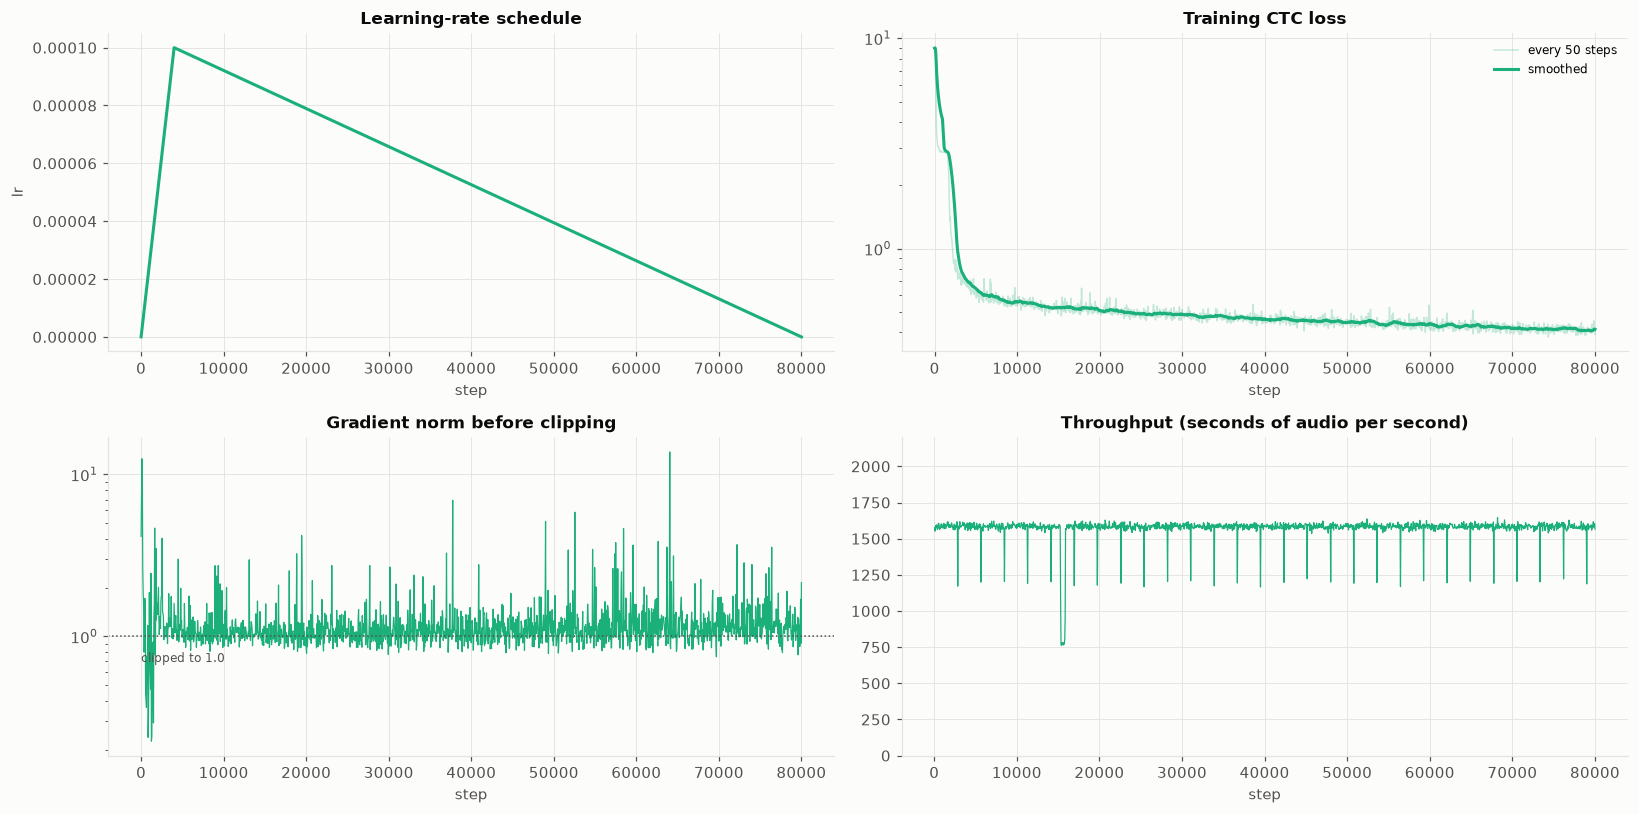

,value
optimizer steps,80000
epochs,28
GPU hours (1 × L40S),8.41
median s / step,0.375
audio seconds per second,1584
peak GPU memory (GB),10.85
max gradient norm (before clipping),13.79
steps with gradient norm > 1 (clipped),70 % of logged steps
non-finite losses,0
"training loss, first 1k steps → last 1k steps",4.060 → 0.414


In [3]:
tl = pd.read_csv(RUNS / MODEL / "train_log.csv"); el = pd.read_csv(RUNS / MODEL / "eval_log.csv")
c = COLOR[MODEL]
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
axes[0, 0].plot(tl.step, tl.lr, color=c); axes[0, 0].set(title="Learning-rate schedule", xlabel="step", ylabel="lr")
axes[0, 1].plot(tl.step, tl.loss, color=c, alpha=.25, lw=1, label="every 50 steps")
axes[0, 1].plot(tl.step, tl.loss.rolling(20, min_periods=1).mean(), color=c, label="smoothed")
axes[0, 1].set(title="Training CTC loss", xlabel="step", yscale="log"); axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(tl.step, tl.grad_norm, color=c, lw=.8); axes[1, 0].axhline(1.0, color=INK2, ls=":", lw=1)
axes[1, 0].text(0, .8, "clipped to 1.0", ha="left", va="top", fontsize=8, color=INK2)
axes[1, 0].set(title="Gradient norm before clipping", xlabel="step", yscale="log")
axes[1, 1].plot(tl.step.iloc[1:], tl.audio_sec_per_sec.iloc[1:], color=c, lw=.8)
axes[1, 1].set(title="Throughput (seconds of audio per second)", xlabel="step", ylim=(0, 2200))
plt.tight_layout(); plt.show()

r = tl.iloc[1:]
stats = {"optimizer steps": int(tl.step.max()), "epochs": int(tl.epoch.max()),
         "GPU hours (1 × L40S)": round((r.sec_per_step * tl.step.diff().iloc[1:]).sum() / 3600, 2),
         "median s / step": round(r.sec_per_step.median(), 3), "audio seconds per second": round(r.audio_sec_per_sec.median()),
         "peak GPU memory (GB)": round(tl.max_mem_gb.max(), 2), "max gradient norm (before clipping)": round(tl.grad_norm.max(), 2),
         "steps with gradient norm > 1 (clipped)": f"{100 * (tl.grad_norm > 1).mean():.0f} % of logged steps",
         "non-finite losses": int((~np.isfinite(tl.loss)).sum()),
         "training loss, first 1k steps → last 1k steps": f"{tl[tl.step <= 1000].loss.mean():.3f} → {tl[tl.step > tl.step.max() - 1000].loss.mean():.3f}"}
display(pd.Series(stats, name="value").to_frame())

## 4 · Validation and checkpoint selection
Every 2,000 (B460: 4,000) steps the model is decoded (greedy) on the fixed dev set: 2,000 clean utterances and
2,000 noisy ones (dev speakers, **held-out MUSAN noise files**, 0–20 dB). The checkpoint with the lowest **mean**
of the two WERs is saved as `best/`; that is the model published and evaluated below.

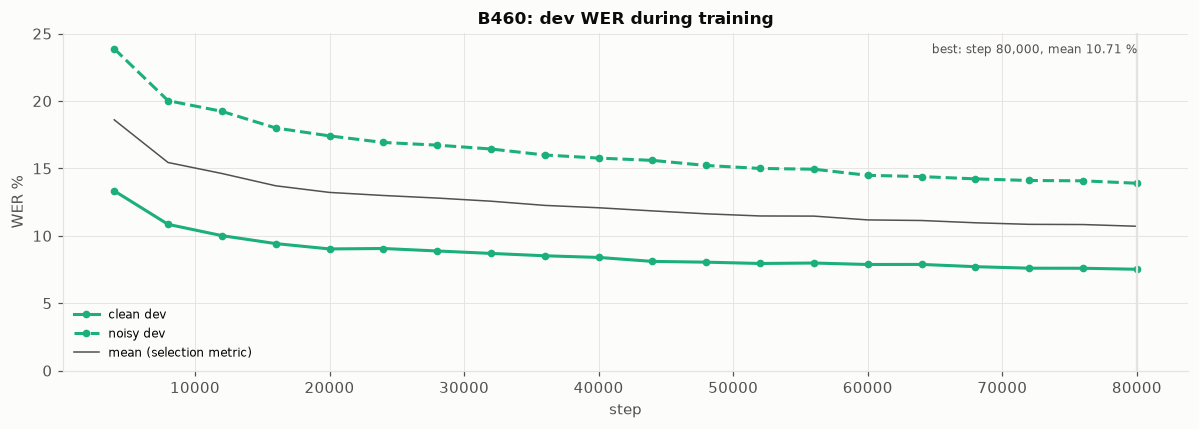

,wer_clean %,wer_noisy %,wer_avg %,cer_clean %,cer_noisy %,empty_hyp_frac %
step,,,,,,
4000,13.34,23.88,18.61,4.26,9.94,0.02
8000,10.85,20.03,15.44,3.56,8.50,0.00
12000,10.01,19.23,14.62,3.36,8.11,0.00
16000,9.42,18.00,13.71,3.23,7.66,0.00
20000,9.03,17.41,13.22,3.11,7.28,0.00
24000,9.06,16.93,12.99,3.11,7.22,0.00
28000,8.88,16.73,12.80,3.05,7.11,0.00
32000,8.70,16.44,12.57,3.03,6.96,0.00
36000,8.52,16.00,12.26,2.99,6.84,0.00


In [4]:
best = el.loc[el.wer_avg.idxmin()]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(el.step, el.wer_clean * 100, color=c, marker="o", ms=4, label="clean dev")
ax.plot(el.step, el.wer_noisy * 100, color=c, marker="o", ms=4, ls="--", label="noisy dev")
ax.plot(el.step, el.wer_avg * 100, color=INK2, lw=1, label="mean (selection metric)")
ax.axvline(best.step, color=GRID, lw=1.5)
ax.annotate(f"best: step {int(best.step):,}, mean {best.wer_avg*100:.2f} %", (best.step, .97), xycoords=("data", "axes fraction"),
            ha="right", va="top", fontsize=8, color=INK2)
top = el.wer_noisy.iloc[1:].max() * 100 * 1.25 if len(el) > 1 else 100
ax.set(title=f"{MODEL}: dev WER during training", xlabel="step", ylabel="WER %", ylim=(0, min(top, 100))); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
t = el[["step", "wer_clean", "wer_noisy", "wer_avg", "cer_clean", "cer_noisy", "empty_hyp_frac"]].copy()
t[t.columns[1:]] = t[t.columns[1:]] * 100
display(t.set_index("step").round(2).rename(columns=lambda s: s + " %"))

How the transcript of one fixed dev utterance changed during training:

In [5]:
ex = el[["step", "example_hyp"]].copy()
print("REFERENCE:", el.example_ref.iloc[0].strip())
with pd.option_context("display.max_colwidth", 120): display(ex.iloc[np.unique(np.linspace(0, len(ex) - 1, 8).astype(int))].set_index("step"))

REFERENCE: HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED


,example_hyp
step,
4000,HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CHUNKY THE BOY'S RARED
12000,HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CHUNKEY THE BOY'S RORED
24000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKEY THE BOYS ROARED
36000,HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED
44000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED
56000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED
68000,HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED
80000,HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED


## 5 · Test results, greedy decoding (no language model)
Test grid: **test-clean** (2,620 utterances) and **test-other** (2,939, harder speakers) × 17 conditions: clean; white,
pink, brown and ESC-50 noise at 20 / 10 / 5 / 0 dB. Test speakers are never seen in training. **Brown noise and ESC-50
were never used in training** (held-out noise types); white and pink are seen *types* but fresh random samples.

In [6]:
def load(path, name=None):
    s = pd.read_csv(path); s["snr_db"] = s.snr_db.astype(str)
    return s.assign(model=name) if name else s

def pool(s):
    # word-weighted pooling of test-clean + test-other (identical to jiwer on all utterances)
    s = s[s.ls_split.isin(N_WORDS)].copy(); s["w"] = s.ls_split.map(N_WORDS)
    return (s.assign(e=s.wer * s.w, ec=s.cer * s.w).groupby(["model", "noise_type", "snr_db"])[["e", "ec", "w"]].sum()
              .pipe(lambda d: pd.DataFrame({"wer": d.e / d.w, "cer": d.ec / d.w})).reset_index())

SNR = ["clean", "20", "10", "5", "0"]; NOISES = ["esc50", "brown", "white", "pink"]
def grid(s, value="wer"):
    s = s.copy(); s.loc[s.noise_type == "clean", "snr_db"] = "clean"
    g = s.pivot_table(index=["ls_split", "noise_type"], columns="snr_db", values=value) * 100
    return g[[c for c in SNR if c in g.columns]].round(2).astype(object).where(g.notna(), "")

G = load(EVAL / MODEL / "summary.csv", MODEL)
display(Markdown("**WER % per split, noise type and SNR (greedy)**")); display(grid(G))
display(Markdown("**CER % (character error rate)**")); display(grid(G, "cer"))

**WER % per split, noise type and SNR (greedy)**

snr_db                 clean     20     10      5      0
ls_split   noise_type                                   
test.clean brown               4.74   4.75   4.81   4.82
           clean         4.7                            
           esc50               4.93   5.83    7.4  12.42
           pink                4.93   5.79   7.82  14.73
           white               5.12   6.71  10.05  19.43
test.other brown               11.1  11.16  11.39  11.91
           clean       11.09                            
           esc50              11.89  14.98  19.16   27.7
           pink               12.01  15.34  20.89  34.38
           white              12.89  18.98  27.08   42.9

**CER % (character error rate)**

snr_db                clean    20    10      5      0
ls_split   noise_type                                
test.clean brown             1.34  1.35   1.37   1.38
           clean       1.32                          
           esc50             1.42  1.83   2.51    5.1
           pink              1.42  1.79   2.67   5.98
           white             1.51  2.21   3.72    8.5
test.other brown             3.92  3.96    4.1   4.34
           clean       3.91                          
           esc50             4.35  5.88   8.21  13.26
           pink              4.39  6.05    9.1  16.95
           white             4.82  7.95  12.46  22.22

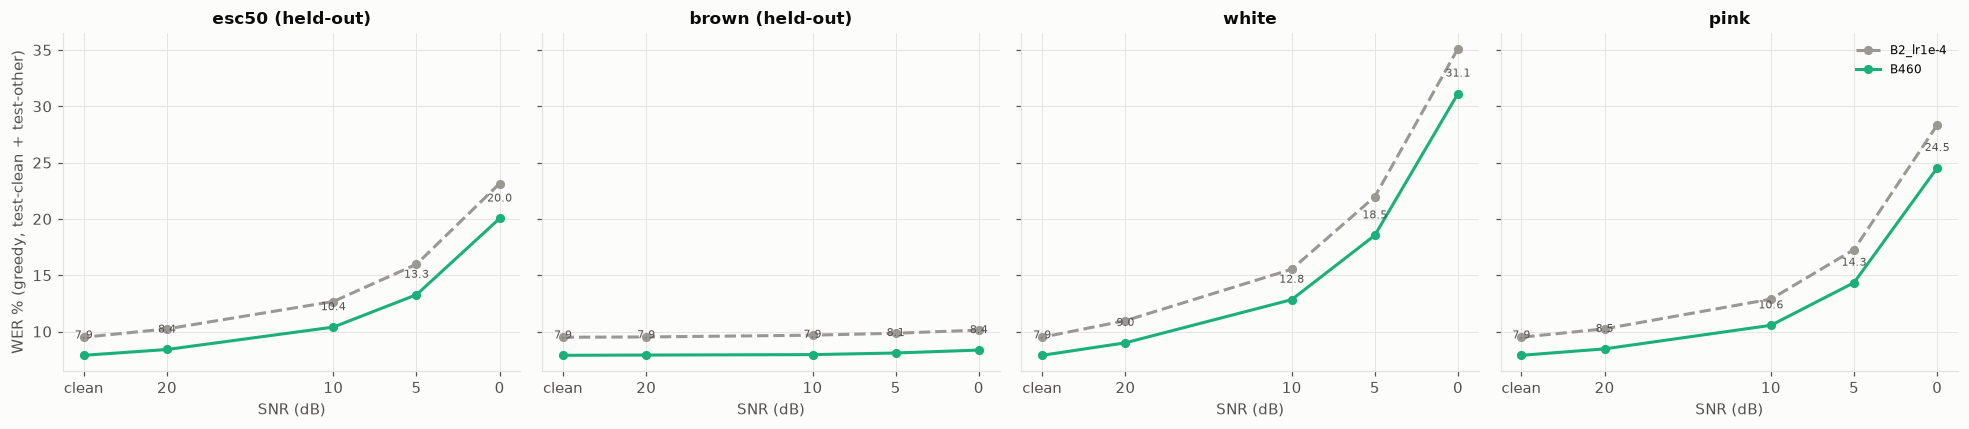

In [7]:
gp = pool(G); X = {"clean": 25, "20": 20, "10": 10, "5": 5, "0": 0}
P = pool(load(EVAL / PARENT / "summary.csv", PARENT))
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, nt in zip(axes, NOISES):
    for name, d, ls in [(PARENT, P, "--"), (MODEL, gp, "-")]:
        q = d[d.noise_type.isin([nt, "clean"])].copy(); q["x"] = q.snr_db.map(X); q = q.sort_values("x")
        ax.plot(q.x, q.wer * 100, marker="o", ms=5, ls=ls, color=COLOR[name], label=name)
        if name == MODEL:
            for x, y in zip(q.x, q.wer * 100):
                ax.text(x, y + 1.5, f"{y:.1f}", ha="center", fontsize=7, color=INK2)
    ax.set_xticks(list(X.values()), SNR); ax.invert_xaxis()
    ax.set(title=nt + (" (held-out)" if nt in ("esc50", "brown") else ""), xlabel="SNR (dB)")
axes[0].set(ylabel="WER % (greedy, test-clean + test-other)"); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6 · Test results with the 4-gram language model
Beam search (pyctcdecode + KenLM) with the official LibriSpeech 4-gram LM: α 0.8, β 2.0, beam 50 (α and β were tuned
on the dev set, once, for Model B, and reused for every model).

In [8]:
L = load(EVAL / f"{MODEL}_lm4" / "test_summary.csv", MODEL)
display(Markdown("**WER % with the 4-gram LM**")); display(grid(L))
lp = pool(L)
def head(p):
    out = {}
    for nt in NOISES:
        out[f"{nt} 0–5 dB"] = p[(p.noise_type == nt) & p.snr_db.isin(["0", "5"])].wer.mean() * 100
    out["all noisy, mean"] = p[p.noise_type != "clean"].wer.mean() * 100
    return out
def split_clean(s, sp): return s[(s.ls_split == sp) & (s.noise_type == "clean")].wer.iloc[0] * 100
H = pd.DataFrame({"greedy": {"test-clean": split_clean(G, "test.clean"), "test-other": split_clean(G, "test.other"), **head(gp)},
                  "4-gram LM": {"test-clean": split_clean(L, "test.clean"), "test-other": split_clean(L, "test.other"), **head(lp)}})
H["LM gain (points)"] = H["greedy"] - H["4-gram LM"]; H["relative %"] = 100 * H["LM gain (points)"] / H["greedy"]
display(H.round(2))
dm = EVAL / f"{MODEL}_lm4" / "dev_metrics.json"
if dm.exists():
    d = json.load(open(dm))
    display(Markdown(f"Dev set with the LM: clean pooled **{d['wer_clean_pooled']*100:.2f} %**, noisy pooled **{d['wer_noisy_pooled']*100:.2f} %**."))
grid_f = EVAL / f"{MODEL}_lm4" / "lm_grid_dev.csv"
if grid_f.exists():
    g = pd.read_csv(grid_f); display(Markdown("**α / β grid on dev (mean of clean and noisy dev WER %)**"))
    display((g.pivot_table(index="alpha", columns="beta", values="wer_avg") * 100).round(2))

**WER % with the 4-gram LM**

snr_db                clean    20     10      5      0
ls_split   noise_type                                 
test.clean brown             2.99    3.0   3.08   3.07
           clean       2.97                           
           esc50             3.16   3.84   4.91   8.98
           pink              3.13   3.73    5.1  10.48
           white             3.32   4.37   6.81  14.31
test.other brown              7.6   7.71   7.88   8.21
           clean       7.58                           
           esc50             8.32   10.7  14.35  22.43
           pink              8.23  10.95  15.95  28.56
           white             8.94  13.96  21.13  36.22

,greedy,4-gram LM,LM gain (points),relative %
test-clean,4.70,2.97,1.73,36.87
test-other,11.09,7.58,3.52,31.72
esc50 0–5 dB,16.66,12.66,4.00,24.01
brown 0–5 dB,8.22,5.56,2.67,32.43
white 0–5 dB,24.84,19.60,5.24,21.11
pink 0–5 dB,19.44,15.01,4.43,22.80
"all noisy, mean",13.36,9.85,3.52,26.32


Dev set with the LM: clean pooled **4.96 %**, noisy pooled **10.30 %**.

## 7 · Harder held-out conditions (greedy)
Real measured room impulse responses (rooms never used in training, alone and combined with ESC-50), and noise at
**−5 dB**, below the 0–20 dB training range.

In [9]:
order = ["reverb+clean", "reverb+esc50 10", "reverb+esc50 5", "reverb+esc50 0", "esc50 -5", "pink -5", "white -5"]
def ext(name):
    p = pool(load(EVAL / f"{name}_ext" / "summary.csv", name))
    p["condition"] = (p.noise_type + " " + p.snr_db.replace("clean", "")).str.strip()
    return p.set_index("condition").wer.reindex(order) * 100
E = pd.DataFrame({MODEL: ext(MODEL)})
if (EVAL / f"{PARENT}_ext" / "summary.csv").exists():
    E.insert(0, PARENT, ext(PARENT)); E["change (points)"] = E[MODEL] - E[PARENT]
E.index = [i.replace("reverb+clean", "real-room reverb, no noise").replace("reverb+esc50", "reverb + ESC-50") + (" dB" if i[-1].isdigit() else "") for i in E.index]
display(E.round(2))

,B2_lr1e-4,B460,change (points)
"real-room reverb, no noise",20.30,17.89,-2.41
reverb + ESC-50 10 dB,29.82,26.72,-3.10
reverb + ESC-50 5 dB,35.92,32.61,-3.31
reverb + ESC-50 0 dB,46.73,43.01,-3.73
esc50 -5 dB,36.85,32.91,-3.94
pink -5 dB,53.86,49.57,-4.29
white -5 dB,59.25,55.24,-4.00


## 8 · Word-level error detection (preview of objective O3)
Every output word gets a confidence from the CTC posteriors. **AUROC** measures how well low confidence ranks wrong
words above correct ones (0.5 = random, 1 = perfect; target ≥ 0.75). From M5 on, a trained detector (gradient-boosted
trees on 14 word features, `scripts/error_detector.py`) replaces raw confidence; its results are shown when available.

,value
"AUROC, mean frame confidence (greedy)",0.894
"AUROC, minimum frame confidence (greedy)",0.862


**Error detectors on the LM output, all 17 test conditions** (raw = 1 − confidence; isotonic = calibrated confidence; logreg / gbm = trained on dev)

,auroc,ece,recall_at_30pct,precision_at_0.5,recall_at_0.5,flagged_frac_at_0.5
raw,0.863,0.040,0.805,0.740,0.035,0.004
isotonic,0.863,0.006,0.805,0.594,0.298,0.041
logreg,0.893,0.007,0.869,0.672,0.340,0.041
gbm,0.894,0.007,0.866,0.688,0.341,0.040


Selected detector: **gbm**. O3 targets: AUROC ≥ 0.75, ECE ≤ 0.10, ≥ 70 % of errors in the riskiest 30 % of words (`recall_at_30pct`).

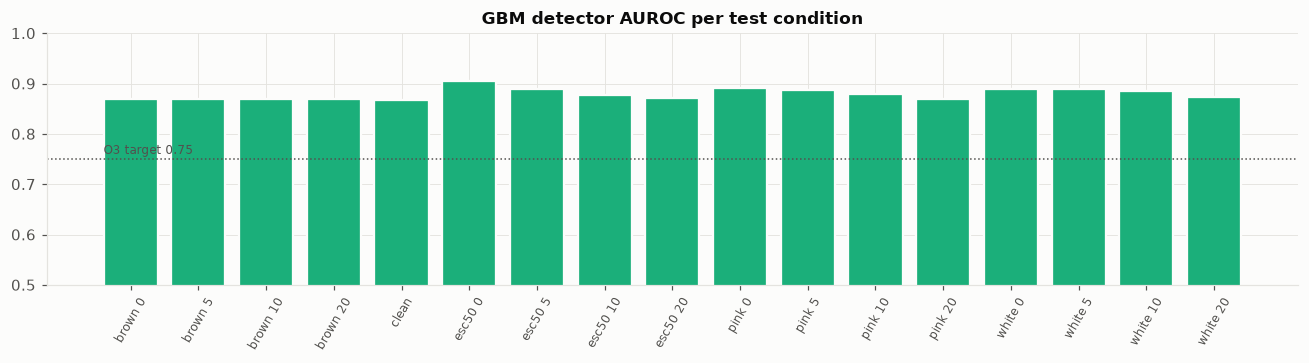

In [10]:
mg = json.load(open(EVAL / MODEL / "metrics.json"))
display(pd.Series({"AUROC, mean frame confidence (greedy)": round(mg["word_auroc_conf_mean"], 3),
                   "AUROC, minimum frame confidence (greedy)": round(mg["word_auroc_conf_min"], 3)}, name="value").to_frame())
det = EVAL / f"{MODEL}_lm4" / "error_detector"
if (det / "metrics.json").exists():
    dm = json.load(open(det / "metrics.json"))
    t = pd.DataFrame({k: v for k, v in dm.items() if isinstance(v, dict) and isinstance(v.get("auroc"), (int, float))}).T
    t = t[["auroc", "ece", "recall_at_30pct", "precision_at_0.5", "recall_at_0.5", "flagged_frac_at_0.5"]].astype(float)
    display(Markdown("**Error detectors on the LM output, all 17 test conditions** (raw = 1 − confidence; isotonic = calibrated confidence; logreg / gbm = trained on dev)"))
    display(t.round(3))
    display(Markdown(f"Selected detector: **{dm.get('selected', 'gbm')}**. O3 targets: AUROC ≥ 0.75, ECE ≤ 0.10, ≥ 70 % of errors in the riskiest 30 % of words (`recall_at_30pct`)."))
    pc = pd.read_csv(det / "per_condition.csv")
    pc["condition"] = (pc.noise_type + " " + pc.snr_db.astype(str).str.replace("nan", "").str.replace("clean", "")).str.strip()
    fig, ax = plt.subplots(figsize=(12, 3.4))
    ax.bar(pc.condition, pc.auroc, color=COLOR[MODEL], edgecolor=SURF, lw=1.5); ax.axhline(.75, color=INK2, ls=":", lw=1)
    ax.text(-.4, .76, "O3 target 0.75", ha="left", fontsize=8, color=INK2)
    ax.set(title="GBM detector AUROC per test condition", ylim=(.5, 1)); ax.tick_params(axis="x", rotation=60, labelsize=8)
    plt.tight_layout(); plt.show()
else:
    print("No trained detector for this model (detectors were trained for B and the M5 models).")

## 9 · Comparison with B2_lr1e-4
Same table for both models; negative change = this model is better.

In [11]:
def summary_row(name):
    s = load(EVAL / name / "summary.csv", name); p = pool(s)
    r = {"test-clean": split_clean(s, "test.clean"), "test-other": split_clean(s, "test.other"), **head(p)}
    f = EVAL / f"{name}_lm4" / "test_summary.csv"
    if f.exists():
        l = load(f, name); r["test-clean, LM"] = split_clean(l, "test.clean"); r["test-other, LM"] = split_clean(l, "test.other")
        r["esc50 0–5 dB, LM"] = head(pool(l))["esc50 0–5 dB"]
    return r
CMP = pd.DataFrame({PARENT: summary_row(PARENT), MODEL: summary_row(MODEL)})
CMP["change (points)"] = CMP[MODEL] - CMP[PARENT]; CMP["relative %"] = 100 * CMP["change (points)"] / CMP[PARENT]
if (RUNS / PARENT / "eval_log.csv").exists():
    pe = pd.read_csv(RUNS / PARENT / "eval_log.csv"); pb = pe.loc[pe.wer_avg.idxmin()]
    CMP.loc["dev WER mean (best ckpt)"] = [pb.wer_avg * 100, best.wer_avg * 100, (best.wer_avg - pb.wer_avg) * 100, 100 * (best.wer_avg - pb.wer_avg) / pb.wer_avg]
display(CMP.round(2))

,B2_lr1e-4,B460,change (points),relative %
test-clean,5.89,4.70,-1.19,-20.24
test-other,13.11,11.09,-2.02,-15.40
esc50 0–5 dB,19.56,16.66,-2.90,-14.85
brown 0–5 dB,9.99,8.22,-1.76,-17.67
white 0–5 dB,28.56,24.84,-3.71,-13.00
pink 0–5 dB,22.81,19.44,-3.37,-14.78
"all noisy, mean",15.85,13.36,-2.48,-15.66
"test-clean, LM",3.67,2.97,-0.70,-19.13
"test-other, LM",9.18,7.58,-1.60,-17.48
"esc50 0–5 dB, LM",14.82,12.66,-2.16,-14.58


## 10 · Live transcription example
A 34-second LibriSpeech test-other passage (speaker 3080, CC BY 4.0) shipped with the app in
`deployment/app/examples/`: once clean and once with **white noise at 5 dB SNR**. Greedy decoding on CPU, no LM.
The cell uses the local checkpoint `experiments/runs/B460/best/` when it exists (on the server). On another machine set
`DOWNLOAD = True` to fetch the model from Hugging Face (≈ 380 MB).

In [12]:
DOWNLOAD = False
import soundfile as sf, torch, jiwer
from group9_ds_ai_lab.data.dataset import zscore
from group9_ds_ai_lab.inference.decode import greedy_words
local = RUNS / MODEL / "best"
src = local if (local / "model.safetensors").exists() else (HF_ID if DOWNLOAD else None)
if src is None:
    print(f"Model weights not found locally. Set DOWNLOAD = True to load {HF_ID} from Hugging Face.")
else:
    from transformers import Wav2Vec2ForCTC
    from transformers.utils import logging as hf_logging
    hf_logging.disable_progress_bar(); hf_logging.set_verbosity_error()
    torch.set_num_threads(4)
    model = Wav2Vec2ForCTC.from_pretrained(str(src)).eval()
    exdir = REPO / "deployment" / "app" / "examples"; ref = (exdir / "reference.txt").read_text().strip()
    rows = []
    for name in ["librispeech_clean.flac", "librispeech_white_noise_5dB.flac"]:
        x, sr = sf.read(exdir / name, dtype="float32")
        with torch.no_grad():
            logp = torch.log_softmax(model(torch.from_numpy(zscore(x))[None]).logits[0].float(), -1).numpy()
        hyp, words = greedy_words(logp)
        low = [w["word"] for w in words if w["conf_mean"] < 0.7]
        rows.append({"audio": name.replace("librispeech_", "").replace(".flac", ""), "WER %": round(100 * jiwer.wer(ref, hyp), 2),
                     "words": len(words), "low-confidence words (< 0.7)": " ".join(low[:15]), "transcript (first 200 chars)": hyp[:200]})
    print("REFERENCE (first 200 chars):", ref[:200])
    with pd.option_context("display.max_colwidth", 210): display(pd.DataFrame(rows).set_index("audio"))

REFERENCE (first 200 chars): WOULD IT WOULD LEAVE ME AND THEN I COULD BELIEVE I SHALL NOT ALWAYS HAVE OCCASION FOR IT MY POOR LADY VAVASOUR IS CARRIED TO THE TOWER AND HER GREAT BELLY COULD NOT EXCUSE HER BECAUSE SHE WAS ACQUAINT


,WER %,words,low-confidence words (< 0.7),transcript (first 200 chars)
audio,,,,
clean,4.49,89,,WOULD IT WOULD LEAVE ME AND THEN I COULD BELIEVE I SHALL NOT ALWAYS HAVE OCCASION FOR IT MY POOR LADY VAVESOR IS CARRIED TO THE TOWER IN HER GREAT BELLY COULD NOT EXCUSE HER BECAUSE SHE WAS ACQUAINTED
white_noise_5dB,16.85,87,WOT HA THE I,WOULD IT WOT MADE ME AND THEN I COULD BELIEVE I SHALL NOT ALWAYS HAVE OCCASION FOR IT MY POOR LADY VAVASOR IS CARRIED TOT POWER AND HA GREAT BELLY COULD NOT EXCUSE HER BECAUSE SHE WAS ACQUIMTED BY SOM


## 11 · Summary

In [13]:
gc, go = split_clean(G, "test.clean"), split_clean(G, "test.other")
lc, lo = split_clean(L, "test.clean"), split_clean(L, "test.other")
display(Markdown(f'''
| | {MODEL} |
|---|---|
| Training | {stats["optimizer steps"]:,} steps, {stats["epochs"]} epochs, {stats["GPU hours (1 × L40S)"]} GPU-hours, {stats["non-finite losses"]} non-finite losses |
| Best checkpoint | step {int(best.step):,}: dev WER clean {best.wer_clean*100:.2f} %, noisy {best.wer_noisy*100:.2f} % |
| Test-clean / test-other, greedy | {gc:.2f} / {go:.2f} % |
| Test-clean / test-other, 4-gram LM | **{lc:.2f} / {lo:.2f} %** |
| Held-out ESC-50 at 0–5 dB, greedy / LM | {head(gp)["esc50 0–5 dB"]:.2f} / **{head(lp)["esc50 0–5 dB"]:.2f} %** |
| White noise at 0–5 dB, greedy / LM | {head(gp)["white 0–5 dB"]:.2f} / {head(lp)["white 0–5 dB"]:.2f} % |
| Real-room reverb (held-out rooms), greedy | {E.loc["real-room reverb, no noise", MODEL]:.2f} % |
| Word-error AUROC of raw confidence | {mg["word_auroc_conf_mean"]:.3f} |
'''))


| | B460 |
|---|---|
| Training | 80,000 steps, 28 epochs, 8.41 GPU-hours, 0 non-finite losses |
| Best checkpoint | step 80,000: dev WER clean 7.52 %, noisy 13.90 % |
| Test-clean / test-other, greedy | 4.70 / 11.09 % |
| Test-clean / test-other, 4-gram LM | **2.97 / 7.58 %** |
| Held-out ESC-50 at 0–5 dB, greedy / LM | 16.66 / **12.66 %** |
| White noise at 0–5 dB, greedy / LM | 24.84 / 19.60 % |
| Real-room reverb (held-out rooms), greedy | 17.89 % |
| Word-error AUROC of raw confidence | 0.894 |


**Observations**
- **More labelled data gave the largest single gain after noise training.** Compared with B2, WER falls by 14–20 % relative in
  every condition: test-clean / test-other with the LM 3.67 / 9.18 → 2.97 / 7.58 %, held-out ESC-50 0–5 dB 14.8 → 12.7 %.
- With the LM it already beats the published wav2vec 2.0 BASE 100 h result (3.4 / 8.0 %).
- Training was as stable as the 100 h runs (no non-finite losses, same memory), and took about 8 GPU-hours.